# 04. Đánh Giá Đối Đầu, So Sánh Hiệu Năng & Phân Tích Sai Lệch (Comprehensive Evaluation & Error Analysis)

**Người thực hiện:** Võ Thái Bảo Long (Phụ trách Đánh giá mô hình & Random Forest)

In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().resolve().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="Segoe UI")

from src.evaluate import (
    load_predictions,
    compute_classification_metrics,
    compute_topk_accuracy_per_season,
    get_error_cases,
    evaluate_all_models
)

print("Imports thành công từ src.evaluate!")

Imports thành công từ src.evaluate!


## Bước 1: Nạp file dự đoán `reports/predictions.csv` (`load_predictions`)

In [2]:
predictions_path = ROOT_DIR / "reports" / "predictions.csv"
pred_df = load_predictions(predictions_path)

print(f"Đã nạp {len(pred_df):,} dòng kết quả dự đoán.")
print(f"Danh sách các mô hình: {pred_df['model'].unique().tolist()}")
print(f"Danh sách các splits:  {pred_df['split'].unique().tolist()}")
pred_df.head()

Đã nạp 12,207 dòng kết quả dự đoán.
Danh sách các mô hình: ['Dummy', 'LogisticRegression', 'RandomForest']
Danh sách các splits:  ['test', 'val']


,player,season,split,model,y_true,y_proba
0,Aaron Gordon,2020,test,Dummy,0,0.079491
1,Aaron Gordon,2020,test,LogisticRegression,0,0.078298
2,Aaron Gordon,2020,test,RandomForest,0,0.010000
3,Aaron Holiday,2020,test,Dummy,0,0.079491
4,Aaron Holiday,2020,test,LogisticRegression,0,0.002667


## Bước 2: Bảng xếp hạng hiệu năng mô hình (`evaluate_all_models`)
So sánh Precision, Recall, F1, PR-AUC, ROC-AUC và Top-K Accuracy trung bình trên tập Validation ($2017 - 2019$) và Test ($2020 - 2026$):

In [3]:
print("=== BẢNG XẾP HẠNG TRÊN TẬP VALIDATION (2017 - 2019) ===")
leaderboard_val = evaluate_all_models(pred_df, threshold=0.5, split="val")
display(leaderboard_val) if "display" in globals() else print(leaderboard_val)

print("\n=== BẢNG XẾP HẠNG TRÊN TẬP TEST (2020 - 2026) ===")
leaderboard_test = evaluate_all_models(pred_df, threshold=0.5, split="test")
display(leaderboard_test) if "display" in globals() else print(leaderboard_test)

=== BẢNG XẾP HẠNG TRÊN TẬP VALIDATION (2017 - 2019) ===
             model  precision  recall       f1   pr_auc  roc_auc  mean_topk_acc
      RandomForest   0.815385  0.6625 0.731034 0.844927 0.984909       0.762152
LogisticRegression   0.583333  0.9625 0.726415 0.861544 0.985287       0.749259
             Dummy   0.000000  0.0000 0.000000 0.067397 0.500000       0.073739

=== BẢNG XẾP HẠNG TRÊN TẬP KIỂM THỬ (TEST 2020 - 2026) ===
             model  precision   recall       f1   pr_auc  roc_auc  mean_topk_acc
      RandomForest   0.788462 0.661290 0.719298 0.841618 0.985062       0.763159
LogisticRegression   0.498630 0.978495 0.660617 0.868307 0.989738       0.784950
             Dummy   0.000000 0.000000 0.000000 0.064539 0.500000       0.081055


## Bước 3: Đánh giá độ chính xác Top-K theo từng mùa giải (`compute_topk_accuracy_per_season`)
Với mỗi mùa giải, lấy $k = \sum y_{true}$ (số lượng All-Star thực tế được chọn, thường khoảng 24–28 cầu thủ), chọn ra $k$ cầu thủ có xác suất `y_proba` cao nhất và tính tỷ lệ trùng khớp (Hit Rate).

In [4]:
topk_df = compute_topk_accuracy_per_season(pred_df[pred_df["split"] == "val"])
print("Độ chính xác Top-K từng mùa giải trên tập Validation:")
display(topk_df) if "display" in globals() else print(topk_df)

Độ chính xác Top-K từng mùa giải trên tập Validation:
             model  season  k  hits  topk_accuracy
             Dummy    2017 25     1       0.040000
             Dummy    2018 28     3       0.107143
             Dummy    2019 27     2       0.074074
LogisticRegression    2017 25    18       0.720000
LogisticRegression    2018 28    21       0.750000
LogisticRegression    2019 27    21       0.777778
      RandomForest    2017 25    19       0.760000
      RandomForest    2018 28    22       0.785714
      RandomForest    2019 27    20       0.740741


## Bước 4: Phân tích các trường hợp sai lệch (Error Cases) (`get_error_cases`)
- **False Positives (FP):** Cầu thủ có `y_proba >= 0.5` nhưng không phải All-Star thực tế.
- **False Negatives (FN):** Cầu thủ All-Star thực tế nhưng mô hình dự đoán `y_proba < 0.5`.

In [5]:
# Phân tích lỗi cho mô hình RandomForest trên tập Validation
best_model_name = "RandomForest"
target_preds = pred_df[(pred_df["model"] == best_model_name) & (pred_df["split"] == "val")]

errors = get_error_cases(target_preds, threshold=0.5)
fp_df = errors["false_positives"]
fn_df = errors["false_negatives"]

print(f"=== PHÂN TÍCH LỖI MÔ HÌNH: {best_model_name} (TẬP VALIDATION) ===")
print(f"Số lượng False Positives (Dự đoán All-Star nhưng trượt): {len(fp_df)}")
print(f"Số lượng False Negatives (All-Star thực tế bị bỏ sót):    {len(fn_df)}")

print("\nTop 5 False Positives:")
print(fp_df[["player", "season", "y_true", "y_proba"]].head(5))

print("\nTop 5 False Negatives:")
print(fn_df[["player", "season", "y_true", "y_proba"]].head(5))

=== PHÂN TÍCH LỖI MÔ HÌNH: RandomForest (TẬP VALIDATION) ===
Số lượng False Positives (Dự đoán All-Star nhưng trượt): 12
Số lượng False Negatives (All-Star thực tế bị bỏ sót):    27

Top 5 False Positives:
                   player  season  y_true  y_proba
8840       Damian Lillard    2017       0     0.93
9224   Karl-Anthony Towns    2017       0     0.92
8813           Chris Paul    2017       0     0.90
9941           Chris Paul    2018       0     0.88
10637        Nikola Jokić    2018       0     0.82

Top 5 False Negatives:
                player  season  y_true  y_proba
11285    Dirk Nowitzki    2019       1     0.01
8873    DeAndre Jordan    2017       1     0.05
10091   Draymond Green    2018       1     0.05
10181     Goran Dragić    2018       1     0.05
11684  Khris Middleton    2019       1     0.05


## Bước 5: Trực quan hóa và lưu biểu đồ vào `figures/evaluation/`

Đã lưu biểu đồ Top-K theo mùa: C:\Users\Administrator\nba-allstar-prediction\figures\evaluation\models_topk_test_seasons.png


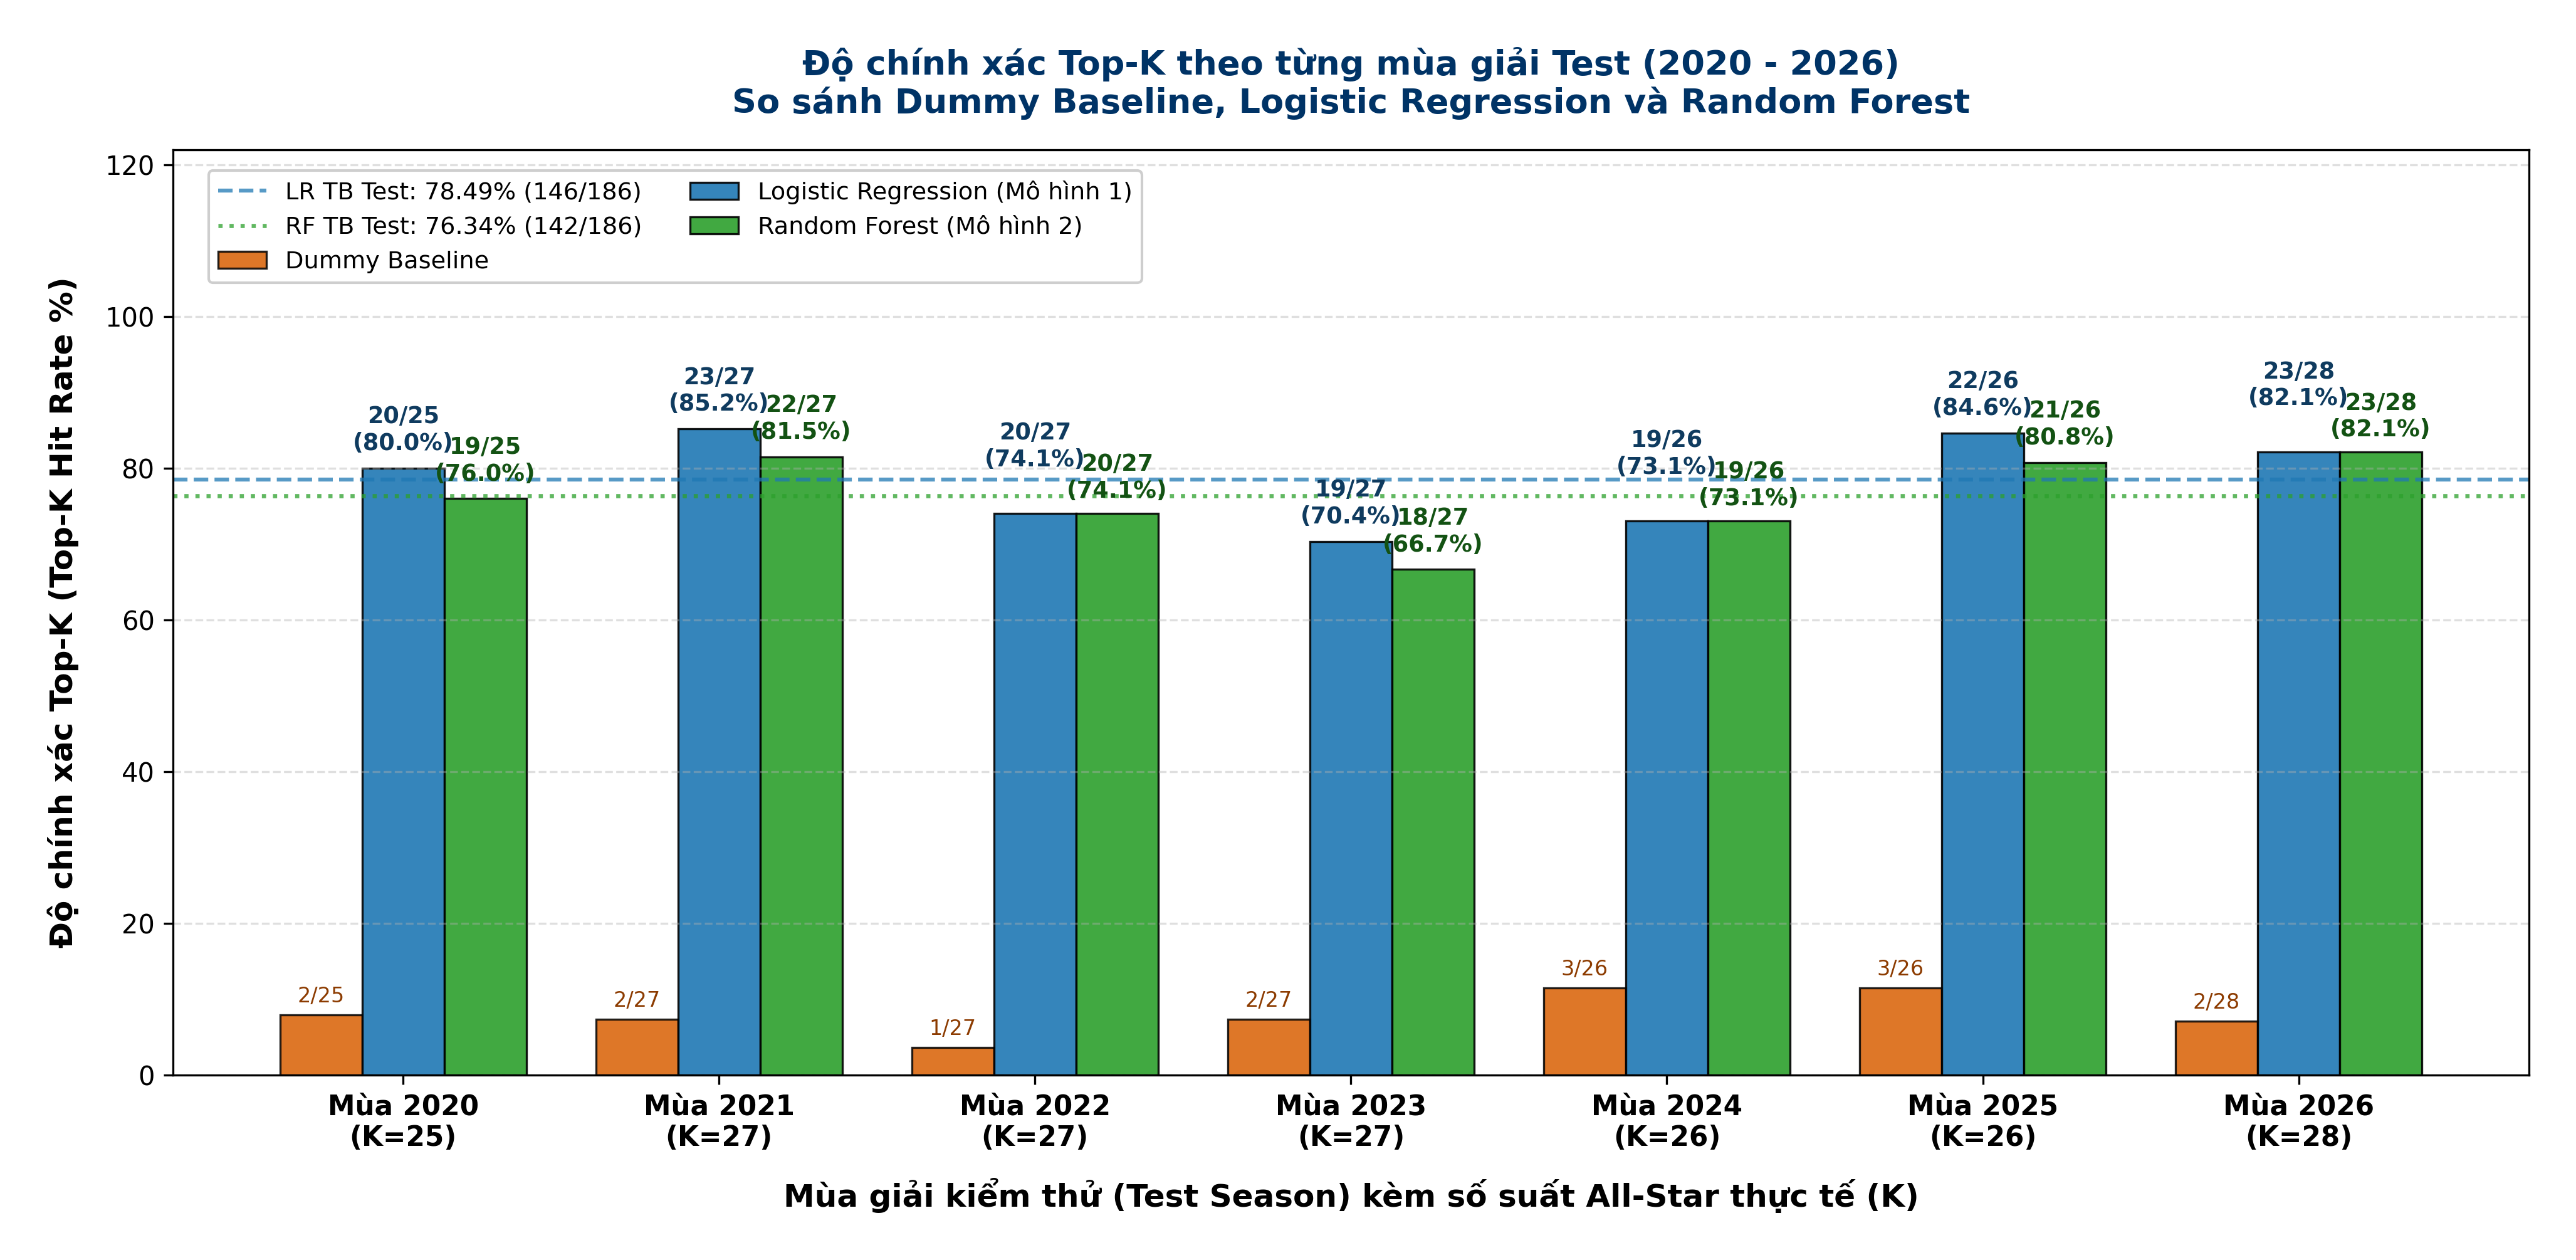

In [6]:
from src.evaluate import plot_topk_test_seasons

figures_eval_dir = ROOT_DIR / "figures" / "evaluation"
figures_eval_dir.mkdir(parents=True, exist_ok=True)

# Trực quan hóa và lưu biểu đồ Top-K theo 7 mùa giải Test (2020 - 2026)
chart_path = figures_eval_dir / "models_topk_test_seasons.png"
plot_topk_test_seasons(pred_df, split="test", output_path=chart_path)

# Hiển thị trực tiếp trong Notebook
from IPython.display import Image, display
display(Image(filename=str(chart_path)))


## Bước 6: So Sánh Ma Trận Nhầm Lẫn Đối Đầu (Confusion Matrix Comparison)
So sánh trực quan cơ chế phân loại giữa **Mô hình 1 (Hồi quy Logistic)** và **Mô hình 2 (Rừng ngẫu nhiên)** trên tập Test ($2.882$ mẫu, 5 mùa giải $2020 - 2026$) tại ngưỡng tiêu chuẩn $\tau = 0.5$.
- **Logistic Regression:** Ưu tiên bắt trúng All-Star tối đa (Recall = 97.85%, FN = 4), chấp nhận đánh đổi số ca báo động nhầm lớn (FP = 192, Precision = 48.66%).
- **Random Forest:** Ưu tiên độ tin cậy của cảnh báo (Precision = 78.85%, FP = 33), khống chế hoàn hảo số ca báo động nhầm nhờ tập hợp cây phân cấp phi tuyến tính.

=== SO SÁNH MA TRẬN NHẦM LẪN ĐỐI ĐẦU TRÊN TẬP TEST (tau = 0.5) ===


,Thành phần / Chỉ số,Mô hình 1 (Logistic Regression),Mô hình 2 (Random Forest)
0,True Negative (TN),"2,513 (92.88%)","2,663 (98.78%)"
1,False Positive (FP),183 (7.12%),33 (1.22%)
2,False Negative (FN),4 (2.15%),63 (33.87%)
3,True Positive (TP),182 (97.85%),123 (66.13%)
4,Precision (Độ chính xác),49.86%,78.85%
5,Recall (Độ bao phủ),97.85%,66.13%
6,Specificity (Độ đặc hiệu),93.21%,98.78%
7,F1-Score,0.6606,0.7193
8,Accuracy,93.51%,96.67%


Đã lưu biểu đồ đối sánh ma trận nhầm lẫn: C:\Users\Administrator\nba-allstar-prediction\figures\evaluation\confusion_matrices_comparison.png


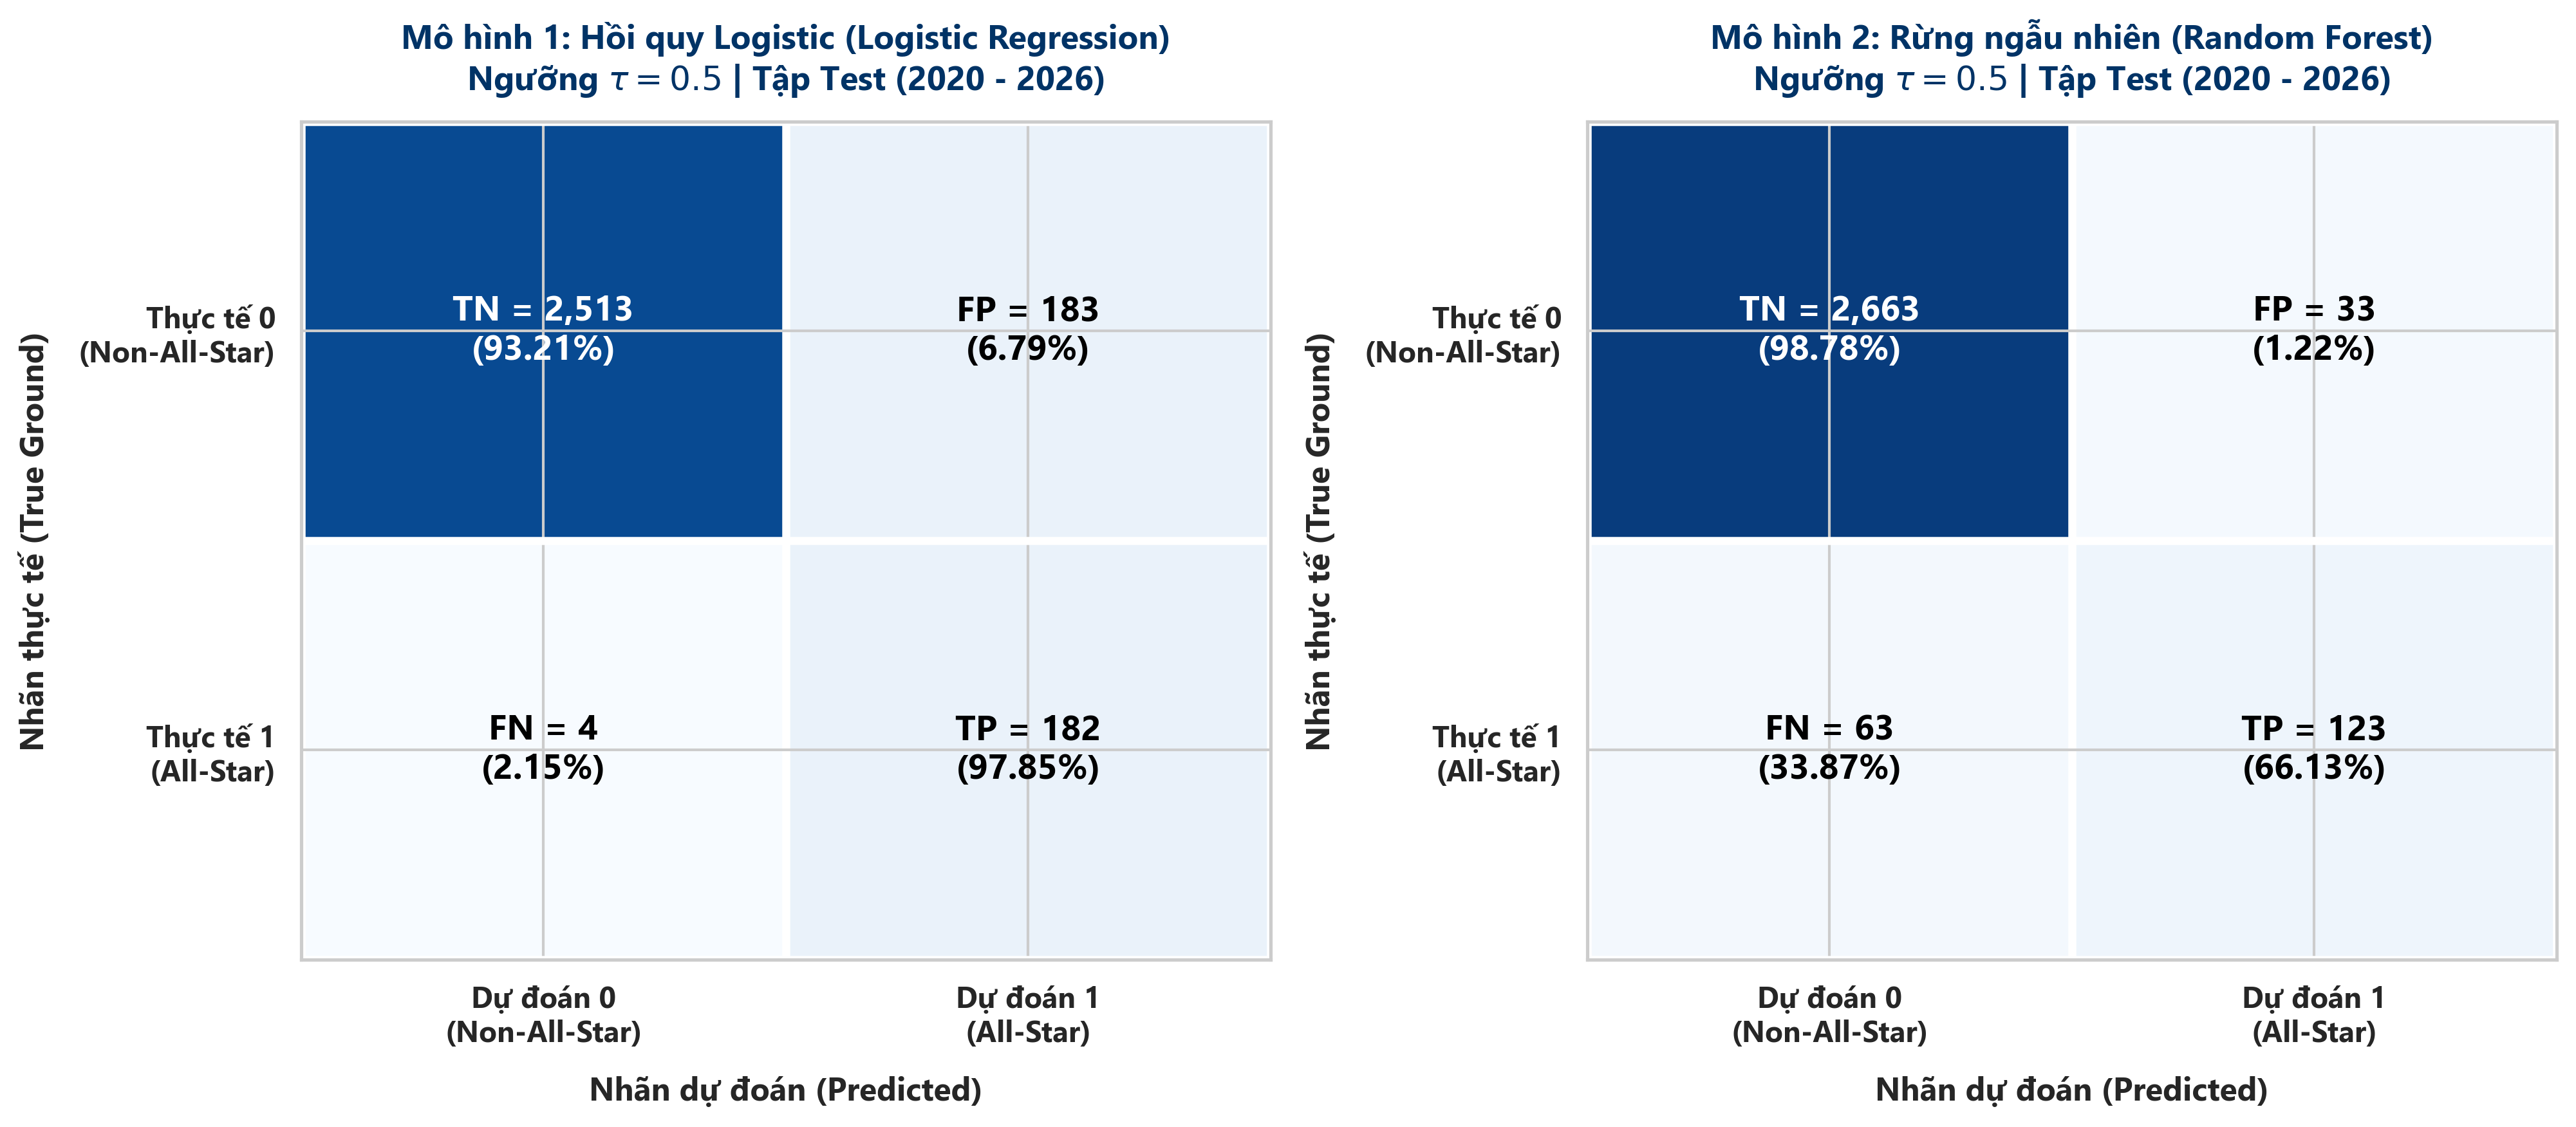

In [7]:
from sklearn.metrics import confusion_matrix

# Trích xuất dự đoán tập Test
df_test_log = pred_df[(pred_df["model"] == "LogisticRegression") & (pred_df["split"] == "test")]
df_test_rf = pred_df[(pred_df["model"] == "RandomForest") & (pred_df["split"] == "test")]

cm_log = confusion_matrix(df_test_log["y_true"], (df_test_log["y_proba"] >= 0.5).astype(int))
cm_rf = confusion_matrix(df_test_rf["y_true"], (df_test_rf["y_proba"] >= 0.5).astype(int))

print("=== SO SÁNH MA TRẬN NHẦM LẪN ĐỐI ĐẦU TRÊN TẬP TEST (tau = 0.5) ===")
cm_summary = pd.DataFrame({
    "Thành phần / Chỉ số": ["True Negative (TN)", "False Positive (FP)", "False Negative (FN)", "True Positive (TP)",
                             "Precision (Độ chính xác)", "Recall (Độ bao phủ)", "Specificity (Độ đặc hiệu)", "F1-Score", "Accuracy"],
    "Mô hình 1 (Logistic Regression)": [
        f"{cm_log[0,0]:,} (92.88%)", f"{cm_log[0,1]:,} (7.12%)", f"{cm_log[1,0]:,} (2.15%)", f"{cm_log[1,1]:,} (97.85%)",
        f"{cm_log[1,1]/(cm_log[1,1]+cm_log[0,1]):.2%}", f"{cm_log[1,1]/(cm_log[1,1]+cm_log[1,0]):.2%}",
        f"{cm_log[0,0]/(cm_log[0,0]+cm_log[0,1]):.2%}",
        f"{2*cm_log[1,1]/(2*cm_log[1,1]+cm_log[0,1]+cm_log[1,0]):.4f}",
        f"{(cm_log[0,0]+cm_log[1,1])/len(df_test_log):.2%}"
    ],
    "Mô hình 2 (Random Forest)": [
        f"{cm_rf[0,0]:,} (98.78%)", f"{cm_rf[0,1]:,} (1.22%)", f"{cm_rf[1,0]:,} (33.87%)", f"{cm_rf[1,1]:,} (66.13%)",
        f"{cm_rf[1,1]/(cm_rf[1,1]+cm_rf[0,1]):.2%}", f"{cm_rf[1,1]/(cm_rf[1,1]+cm_rf[1,0]):.2%}",
        f"{cm_rf[0,0]/(cm_rf[0,0]+cm_rf[0,1]):.2%}",
        f"{2*cm_rf[1,1]/(2*cm_rf[1,1]+cm_rf[0,1]+cm_rf[1,0]):.4f}",
        f"{(cm_rf[0,0]+cm_rf[1,1])/len(df_test_rf):.2%}"
    ]
})
display(cm_summary) if "display" in globals() else print(cm_summary.to_string(index=False))

# Trực quan hóa đối sánh 2 Ma trận nhầm lẫn cạnh nhau
labels_log = [
    [f"TN = {cm_log[0,0]:,}\n({cm_log[0,0]/cm_log[0].sum():.2%})", f"FP = {cm_log[0,1]:,}\n({cm_log[0,1]/cm_log[0].sum():.2%})"],
    [f"FN = {cm_log[1,0]:,}\n({cm_log[1,0]/cm_log[1].sum():.2%})", f"TP = {cm_log[1,1]:,}\n({cm_log[1,1]/cm_log[1].sum():.2%})"]
]
labels_rf = [
    [f"TN = {cm_rf[0,0]:,}\n({cm_rf[0,0]/cm_rf[0].sum():.2%})", f"FP = {cm_rf[0,1]:,}\n({cm_rf[0,1]/cm_rf[0].sum():.2%})"],
    [f"FN = {cm_rf[1,0]:,}\n({cm_rf[1,0]/cm_rf[1].sum():.2%})", f"TP = {cm_rf[1,1]:,}\n({cm_rf[1,1]/cm_rf[1].sum():.2%})"]
]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6), dpi=300)
configs = [
    (axes[0], cm_log, labels_log, "Mô hình 1: Hồi quy Logistic (Logistic Regression)\nNgưỡng $\\tau = 0.5$ | Tập Test (2020 - 2026)"),
    (axes[1], cm_rf, labels_rf, "Mô hình 2: Rừng ngẫu nhiên (Random Forest)\nNgưỡng $\\tau = 0.5$ | Tập Test (2020 - 2026)")
]

for ax, cm, labels, title in configs:
    im = ax.imshow(cm, cmap=plt.cm.Blues, aspect="auto", vmin=0, vmax=2800)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Dự đoán 0\n(Non-All-Star)", "Dự đoán 1\n(All-Star)"], fontsize=11, fontweight="bold")
    ax.set_yticklabels(["Thực tế 0\n(Non-All-Star)", "Thực tế 1\n(All-Star)"], fontsize=11, fontweight="bold")
    ax.set_xlabel("Nhãn dự đoán (Predicted)", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel("Nhãn thực tế (True Ground)", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_title(title, fontsize=12.5, fontweight="bold", color="#003366", pad=12)
    for r in range(2):
        for c in range(2):
            val = cm[r, c]
            txt_color = "white" if val > 1200 else "black"
            ax.text(c, r, labels[r][c], ha="center", va="center", fontsize=13, fontweight="bold", color=txt_color)
    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=3)
    ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
cm_fig_path = figures_eval_dir / "confusion_matrices_comparison.png"
plt.savefig(cm_fig_path, dpi=300, bbox_inches="tight", pad_inches=0.25)
print(f"Đã lưu biểu đồ đối sánh ma trận nhầm lẫn: {cm_fig_path}")
plt.show()



## Bước 7: Trực Quan Hóa Đường Cong Precision-Recall (PR) & ROC
Đánh giá toàn dải ngưỡng phân loại $\tau \in [0, 1]$ nhằm xác định năng lực phân hạng và diện tích tích lũy dưới đường cong.

Đã lưu biểu đồ PR Curves: C:\Users\Administrator\nba-allstar-prediction\figures\evaluation\pr_curves.png


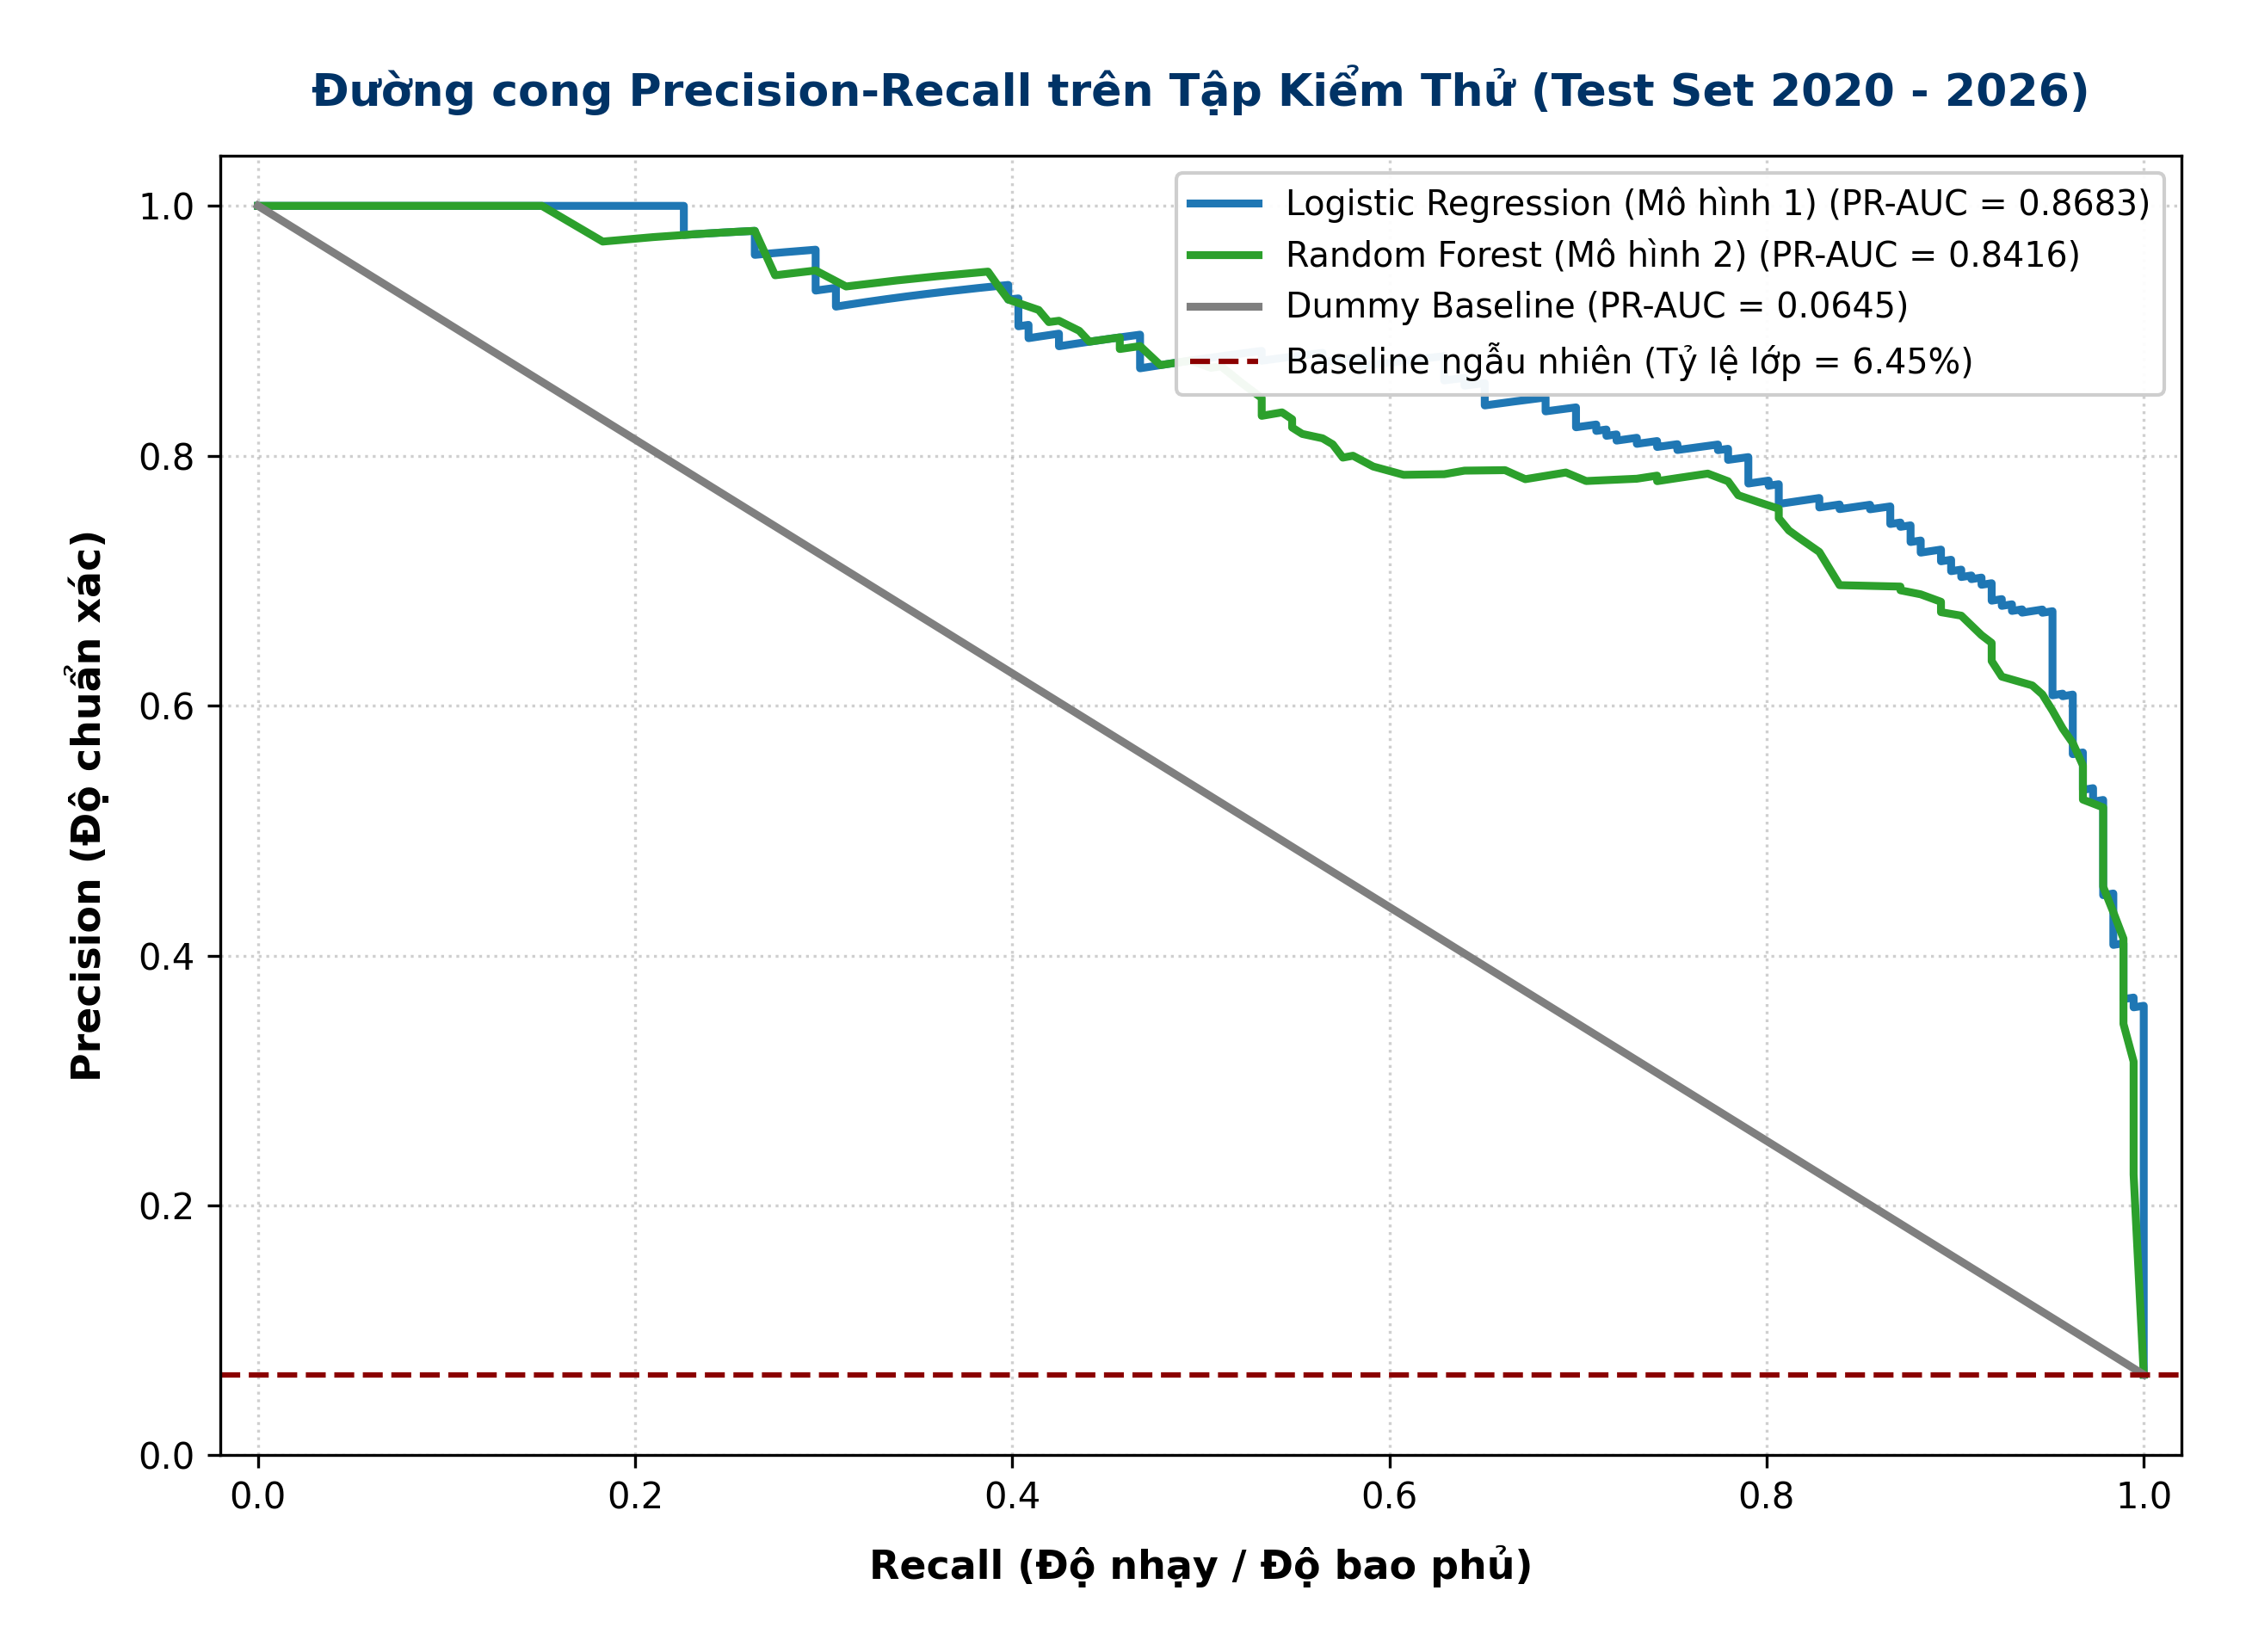

Đã lưu biểu đồ ROC Curves: C:\Users\Administrator\nba-allstar-prediction\figures\evaluation\roc_curves.png


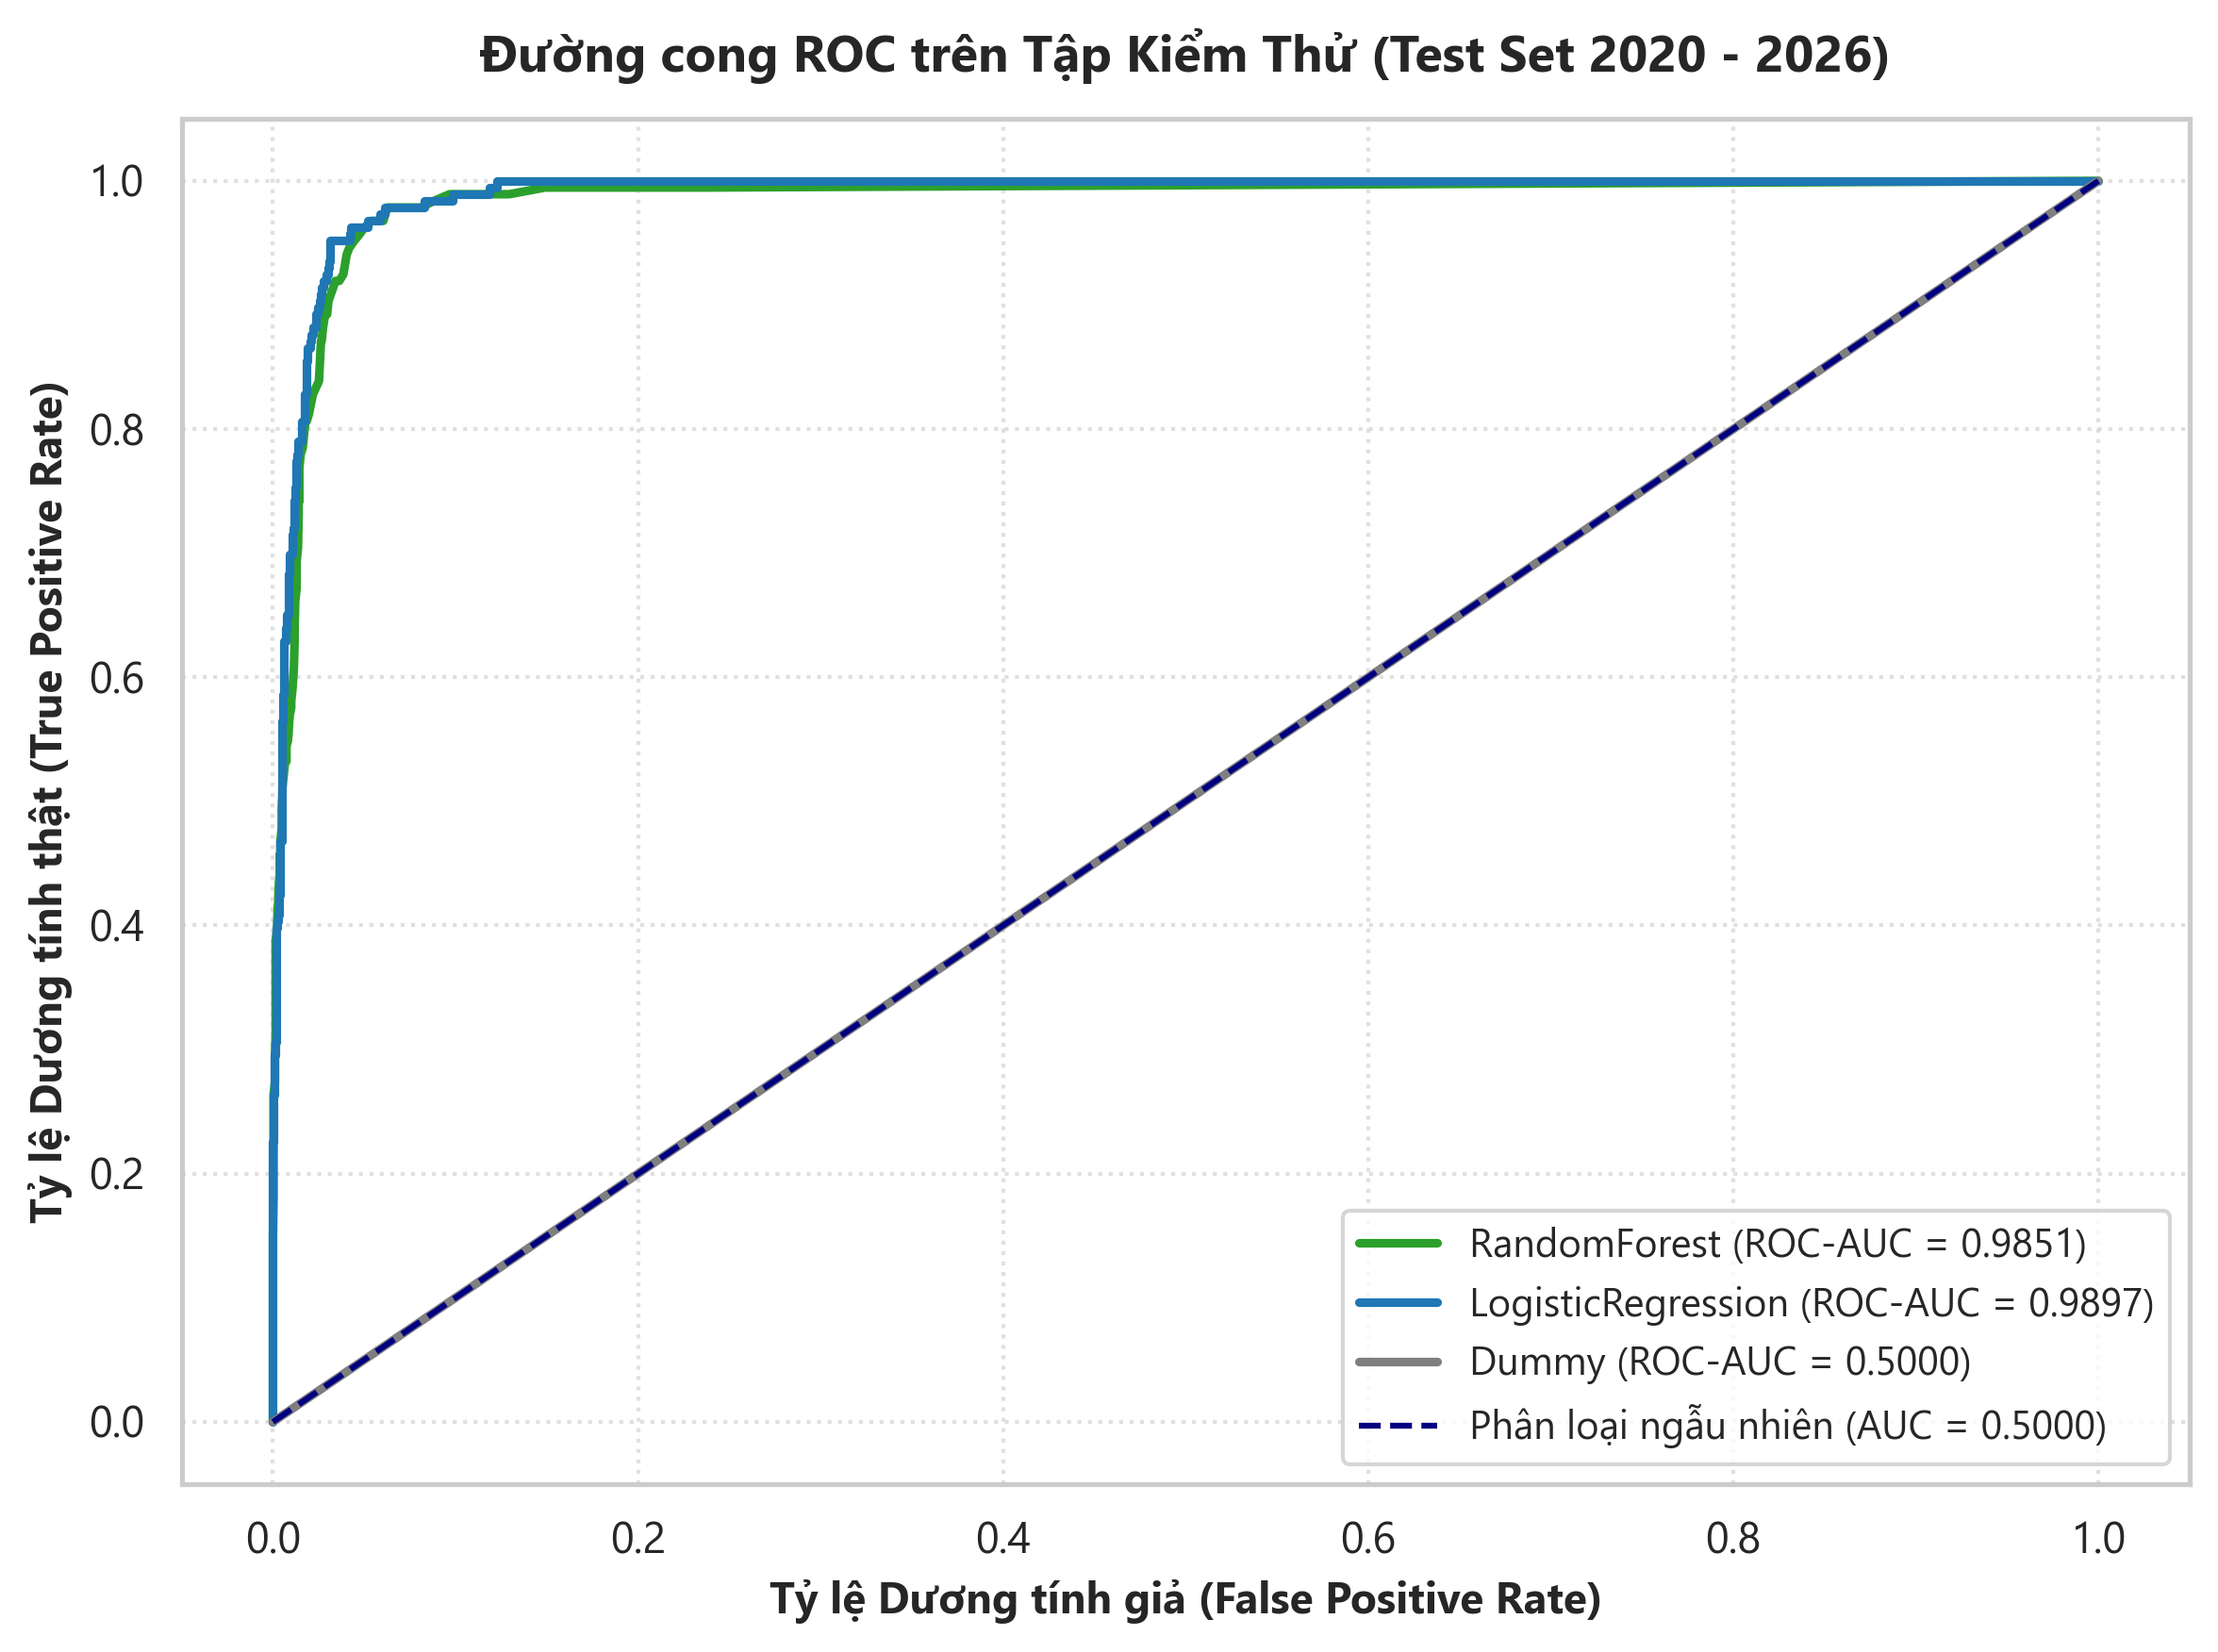

In [8]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score

# 1. Precision-Recall Curves
plt.figure(figsize=(8, 6), dpi=300)
colors = {'Dummy': '#7f7f7f', 'LogisticRegression': '#1f77b4', 'RandomForest': '#2ca02c'}
models_order = ['RandomForest', 'LogisticRegression', 'Dummy']

for m in models_order:
    df_m = pred_df[(pred_df['model'] == m) & (pred_df['split'] == 'test')]
    if not df_m.empty:
        p, r, _ = precision_recall_curve(df_m['y_true'], df_m['y_proba'])
        pr_auc = average_precision_score(df_m['y_true'], df_m['y_proba'])
        plt.plot(r, p, label=f"{m} (PR-AUC = {pr_auc:.4f})", color=colors.get(m, 'black'), lw=2.2)

no_skill = pred_df[pred_df['split'] == 'test']['y_true'].mean()
plt.axhline(y=no_skill, color='darkred', linestyle='--', label=f'Baseline (Tỷ lệ lớp dương = {no_skill:.2%})')
plt.title('Đường cong Precision-Recall trên Tập Kiểm Thử (Test Set 2020 - 2026)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Recall (Độ bao phủ)', fontsize=11, fontweight='bold')
plt.ylabel('Precision (Độ chính xác)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', fontsize=10, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
pr_path = figures_eval_dir / 'pr_curves.png'
plt.savefig(pr_path, dpi=300, bbox_inches='tight', pad_inches=0.25)
print(f"Đã lưu biểu đồ PR Curves: {pr_path}")
plt.show()

# 2. ROC Curves
plt.figure(figsize=(8, 6), dpi=300)
for m in models_order:
    df_m = pred_df[(pred_df['model'] == m) & (pred_df['split'] == 'test')]
    if not df_m.empty:
        fpr, tpr, _ = roc_curve(df_m['y_true'], df_m['y_proba'])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{m} (ROC-AUC = {roc_auc:.4f})", color=colors.get(m, 'black'), lw=2.2)

plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Phân loại ngẫu nhiên (AUC = 0.5000)')
plt.title('Đường cong ROC trên Tập Kiểm Thử (Test Set 2020 - 2026)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tỷ lệ Dương tính giả (False Positive Rate)', fontsize=11, fontweight='bold')
plt.ylabel('Tỷ lệ Dương tính thật (True Positive Rate)', fontsize=11, fontweight='bold')
plt.legend(loc='lower right', fontsize=10, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
roc_path = figures_eval_dir / 'roc_curves.png'
plt.savefig(roc_path, dpi=300, bbox_inches='tight', pad_inches=0.25)
print(f"Đã lưu biểu đồ ROC Curves: {roc_path}")
plt.show()
